In [1]:
import pandas as pd

df = pd.read_csv("/content/sample_data/bestsellers with categories.csv")

print(df.head())
print(df.shape)

                                                Name  \
0                      10-Day Green Smoothie Cleanse   
1                                  11/22/63: A Novel   
2            12 Rules for Life: An Antidote to Chaos   
3                             1984 (Signet Classics)   
4  5,000 Awesome Facts (About Everything!) (Natio...   

                     Author  User Rating  Reviews  Price  Year        Genre  
0                  JJ Smith          4.7    17350      8  2016  Non Fiction  
1              Stephen King          4.6     2052     22  2011      Fiction  
2        Jordan B. Peterson          4.7    18979     15  2018  Non Fiction  
3             George Orwell          4.7    21424      6  2017      Fiction  
4  National Geographic Kids          4.8     7665     12  2019  Non Fiction  
(550, 7)


In [2]:
df.columns = ['name', 'author', 'user_rating', 'reviews', 'price', 'year', 'genre']
print(df.head())

                                                name  \
0                      10-Day Green Smoothie Cleanse   
1                                  11/22/63: A Novel   
2            12 Rules for Life: An Antidote to Chaos   
3                             1984 (Signet Classics)   
4  5,000 Awesome Facts (About Everything!) (Natio...   

                     author  user_rating  reviews  price  year        genre  
0                  JJ Smith          4.7    17350      8  2016  Non Fiction  
1              Stephen King          4.6     2052     22  2011      Fiction  
2        Jordan B. Peterson          4.7    18979     15  2018  Non Fiction  
3             George Orwell          4.7    21424      6  2017      Fiction  
4  National Geographic Kids          4.8     7665     12  2019  Non Fiction  


/tmp/ipykernel_3001/2948982655.py:4: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:navy'` for the same effect.

  sns.barplot(data=df, x ='year',y='reviews', hue="genre", color = 'navy')


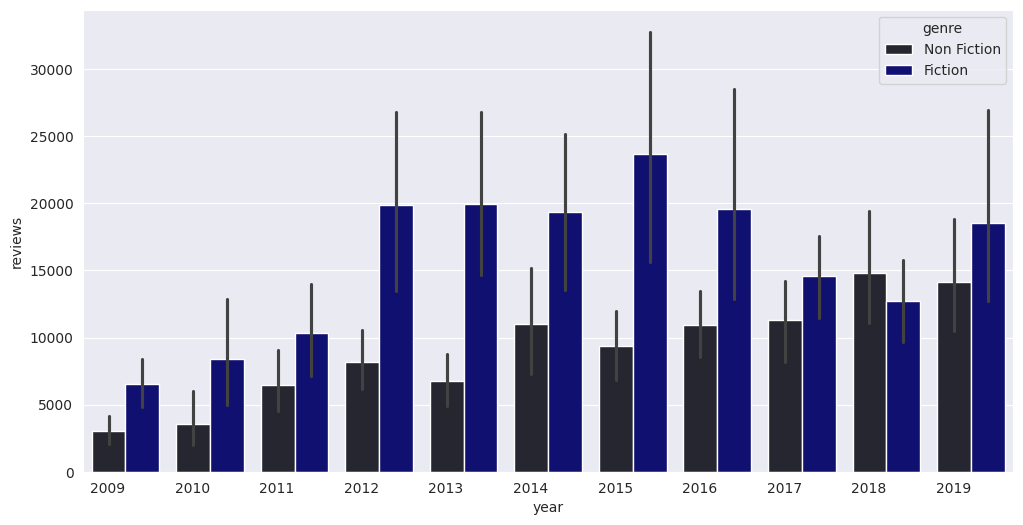

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x ='year',y='reviews', hue="genre", color = 'navy')
plt.xticks(rotation=0, ha='right')
plt.show()

In [3]:
df.isnull().sum()

,0
name,0
author,0
user_rating,0
reviews,0
price,0
year,0
genre,0


In [4]:
df.dtypes

,0
name,object
author,object
user_rating,float64
reviews,int64
price,int64
year,int64
genre,object


In [5]:
#Unigue genre
df['genre'].unique()

array(['Non Fiction', 'Fiction'], dtype=object)

In [6]:
#max price
df['price'].max()

105

In [7]:
#min price
df['price'].min()

0

In [8]:
#average price
df['price'].mean()

np.float64(13.1)

In [9]:
#median price
df['price'].median()

11.0

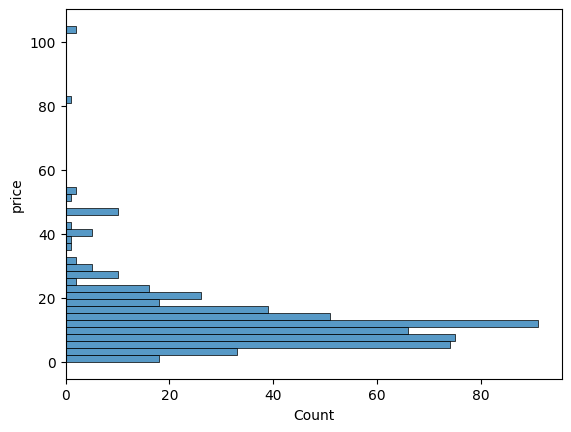

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, y="price")
plt.show()



In [11]:
#max User Raiting
#max price
max_rate = df['user_rating'].max()
print(max_rate)

4.9


In [12]:
#Count max rate
list_max_rate = df[df['user_rating'] == max_rate]
print(len(list_max_rate['name'].unique()))

28


In [13]:
df_groupby = df.groupby(["name"])
print(df_groupby.head())

                                                  name  \
0                        10-Day Green Smoothie Cleanse   
1                                    11/22/63: A Novel   
2              12 Rules for Life: An Antidote to Chaos   
3                               1984 (Signet Classics)   
4    5,000 Awesome Facts (About Everything!) (Natio...   
..                                                 ...   
545       Wrecking Ball (Diary of a Wimpy Kid Book 14)   
546  You Are a Badass: How to Stop Doubting Your Gr...   
547  You Are a Badass: How to Stop Doubting Your Gr...   
548  You Are a Badass: How to Stop Doubting Your Gr...   
549  You Are a Badass: How to Stop Doubting Your Gr...   

                       author  user_rating  reviews  price  year        genre  
0                    JJ Smith          4.7    17350      8  2016  Non Fiction  
1                Stephen King          4.6     2052     22  2011      Fiction  
2          Jordan B. Peterson          4.7    18979     15  201

In [14]:
#book with max count rate
df_result = df.groupby(["name"])["user_rating"].count().sort_values(ascending=False)
print(df_result.head(1))

name
Publication Manual of the American Psychological Association, 6th Edition    10
Name: user_rating, dtype: int64


In [15]:
# max price 2015
year_2015 = df[df['year'] == 2015]
print(year_2015.sort_values('price', ascending=False).head(1))

                                                  name  \
277  Publication Manual of the American Psychologic...   

                                 author  user_rating  reviews  price  year  \
277  American Psychological Association          4.5     8580     46  2015   

           genre  
277  Non Fiction  


In [16]:
# Count Fiction unique books 2010
fiction_2010 = df[(df['year'] == 2010) & (df['genre'] == 'Fiction')]
print(fiction_2010['name'].nunique())

20


In [17]:
# Count books 2010 and 2011 with rate 4.9
rate_4_9 = df[df['user_rating']==4.9]
books_2010_2011 = rate_4_9[(rate_4_9['year'] == 2011)|(rate_4_9['year'] == 2011)]
print(books_2010_2011['name'].nunique())

1


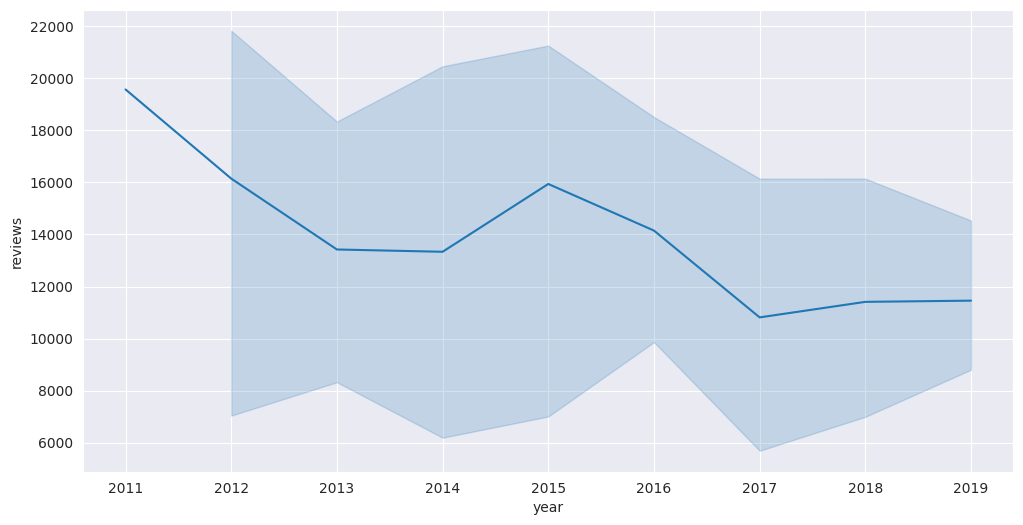

In [51]:
plt.figure(figsize=(12, 6))
sns.set_style("darkgrid")
#data = sns.load_dataset("mpg")
sns.lineplot(x='year', y='reviews', data=rate_4_9)
plt.xticks(rotation=0, ha='center')
plt.show()

In [18]:
# cheaper in 2015
year_2015 = df[df['year'] == 2015]
less_8 = year_2015[year_2015['price'] < 8 ]
less_8.sort_values('price', ascending=True).iloc[-1]

,253
name,Old School (Diary of a Wimpy Kid #10)
author,Jeff Kinney
user_rating,4.8
reviews,6169
price,7
year,2015
genre,Fiction


In [19]:
df_genre = df.groupby(['genre'])
print(df_genre)

In [20]:
#max price for Fiction
df_agg_fict = df_genre.agg({"price": ["max", "min"]})
print(df_agg_fict)

row = df_agg_fict.iloc[0]
print(f"genre: {row.name}, max price: {row[('price', 'max')]}")

            price    
              max min
genre                
Fiction        82   0
Non Fiction   105   0
genre: Fiction, max price: 82


In [21]:
#min price for Fiction
print(f"genre: {row.name}, min price: {row[('price', 'min')]}")

genre: Fiction, min price: 0


In [22]:
#max price for Non Fiction
row = df_agg_fict.iloc[1]
print(f"genre: {row.name}, max price: {row[('price', 'max')]}")

genre: Non Fiction, max price: 105


In [23]:
#min price for Non Fiction
row = df_agg_fict.iloc[0]
print(f"genre: {row.name}, min price: {row[('price', 'min')]}")

genre: Fiction, min price: 0


In [24]:
df_author = df.groupby(['author'])
print(df_author)
df_agg_author = df_author.agg({"name": ["count"]})
print(df_agg_author)

                            name
                           count
author                          
Abraham Verghese               2
Adam Gasiewski                 1
Adam Mansbach                  1
Adir Levy                      1
Admiral William H. McRaven     1
...                          ...
Walter Isaacson                3
William Davis                  2
William P. Young               2
Wizards RPG Team               3
Zhi Gang Sha                   2

[248 rows x 1 columns]


In [25]:
#size new table
print(df_agg_author.shape)

(248, 1)


In [26]:
#Author's max count books
auth_top_book = df_agg_author.sort_values(('name','count'), ascending=False).head(1)
print(f"author with max books: {auth_top_book['name'].index[0]}")

author with max books: Jeff Kinney


In [27]:
#max count books for author
auth_top_book = df_agg_author.sort_values(('name','count'), ascending=False).head(1)
print(f"max books for top author: {auth_top_book['name'].values[0]}")

max books for top author: [12]


In [28]:
#min author rate
df_agg_mean_rate_for_author = df_author.agg({"user_rating": ["mean"]})
#print(df_agg_mean_rate_for_author)
auth_min_rate = df_agg_mean_rate_for_author.sort_values(('user_rating','mean'), ascending=True).head(1)
#print(auth_min_rate)
print(f"author with min rate: {auth_min_rate['user_rating'].index[0]}")

author with min rate: Donna Tartt


In [29]:
print(f"min rate: {auth_min_rate['user_rating'].values[0]}")

min rate: [3.9]


In [30]:
#first athor of list with max books and max rate
important_info_author = pd.concat([df_agg_author, df_agg_mean_rate_for_author], axis=1)
#print(important_info_author)
print(important_info_author.sort_values(by = [('name','count'),('user_rating','mean')],ascending=[False,False]).head(1))

             name user_rating
            count        mean
author                       
Jeff Kinney    12         4.8


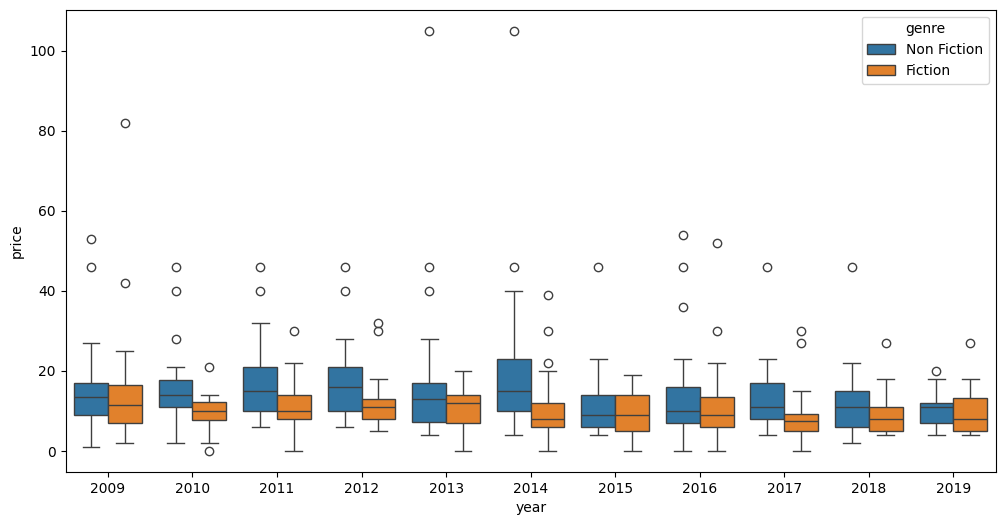

In [32]:
plt.figure(figsize=(12, 6))
sns.boxplot(x="year", y="price", hue="genre", data=df)
plt.show()


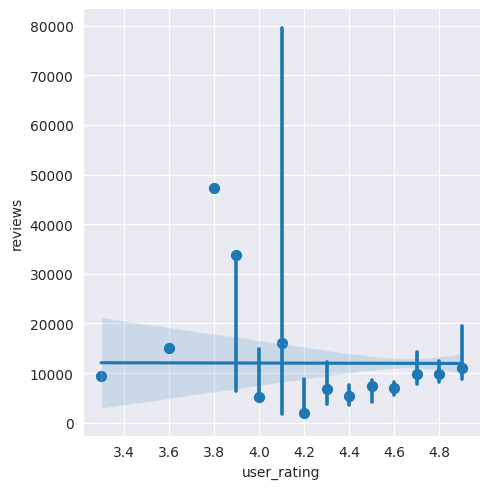

In [33]:
from numpy import median
sns.set_style("darkgrid")
sns.lmplot(x="user_rating", y="reviews", data=df, x_estimator=median)

